In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats
import datetime
import numpy as np
import re 
import seaborn as sns 

In [27]:
compras = pd.read_csv("/home/jpcano/Bavaria/datasets/compras.csv")
productos = pd.read_csv("/home/jpcano/Bavaria/datasets/productos.csv")

# Parte I. Manejo de bases de datos: 

##  # 1. Realice un analisis exploratorio de las tablas

### df compras

In [28]:
compras.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20553 entries, 0 to 20552
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   BRAND          20553 non-null  object 
 1   SKU_ID         0 non-null      float64
 2   UNIT_QUANTITY  0 non-null      float64
 3   VOLUME         0 non-null      float64
 4   GMV            0 non-null      float64
 5   CUSTOMER       0 non-null      float64
 6   ORDER_DATE     0 non-null      float64
 7   POC            0 non-null      float64
dtypes: float64(7), object(1)
memory usage: 1.3+ MB


Se identifica que el archivo csv del dataset de compras esta con un modelo mixto de agrupacion titulos por "," y el texto por "|" , se procede a re descomprimir correctamente.

In [29]:
archivo_path = "/home/jpcano/Bavaria/datasets/compras.csv"

# --- PASO 1: Leer el encabezado titulos sep por coma ","
df_temp = pd.read_csv(archivo_path, sep=',', nrows=1)

# Extraemos la lista de nombres de columna
nombres_columnas = df_temp.columns.tolist()

# --- PASO 2: Leer el cuerpo de los datos con el  (|) y asignar nombres ---
compras = pd.read_csv(
    archivo_path,
    sep='|',
    header=None,       # Le decimos a Pandas que no use la primera fila como encabezado
    skiprows=1         # Le decimos a Pandas que salte la primera fila
)

# --- PASO 3: Asignar los nombres de columna correctos ---
compras.columns = nombres_columnas


In [30]:
compras.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20553 entries, 0 to 20552
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   BRAND          20553 non-null  object 
 1   SKU_ID         20553 non-null  int64  
 2   UNIT_QUANTITY  20553 non-null  int64  
 3   VOLUME         20553 non-null  float64
 4   GMV            20553 non-null  float64
 5   CUSTOMER       20553 non-null  object 
 6   ORDER_DATE     20553 non-null  object 
 7   POC            20553 non-null  object 
dtypes: float64(2), int64(2), object(4)
memory usage: 1.3+ MB


Encontramos tambien que los tipos de datos requieren correcciones por ejemplo la columna ORDER DATE no esta en formato fecha. Pero antes procederemos a normalizar los titulos quitando espacio y pasandolos a minusculas, haremos esto mismo para los datos de la columna brand.

In [31]:
compras.head()

,BRAND,SKU_ID,UNIT_QUANTITY,VOLUME,GMV,CUSTOMER,ORDER_DATE,POC
0,Marca 3,19,1,0.0426,211.20,C707,2025-03-24,SANPABLO
1,MARCA 3,19,1,0.0426,211.20,C1566,2025-03-21,SANPABLO
2,marca 3,19,1,0.0426,154.77,C2883,2025-04-05,SANPABLO
3,M arc a 3,19,1,0.0426,211.20,C27,2025-03-24,VENCEREMOS
4,marca 3,19,1,0.0426,154.77,C27,2025-04-07,VENCEREMOS


In [32]:
columnas_originales = compras.columns

# 2. Creamos un diccionario para almacenar los nuevos nombres.
nuevos_nombres = {}

# 3. Iteramos sobre los nombres originales para aplicar las transformaciones:
for columna in columnas_originales:
    # a. Eliminar espacios iniciales/finales (strip)
    nombre_limpio = columna.strip()
    
    # b. Convertir a minúsculas
    nombre_limpio = nombre_limpio.lower()
    
    # c. Reemplazar espacios por guiones bajos (_)
    nombre_limpio = nombre_limpio.replace(' ', '_')
    
    # Almacenar el mapeo: {'Nombre Original': 'nombre_limpio'}
    nuevos_nombres[columna] = nombre_limpio

# 4. Renombrar las columnas del DataFrame usando el diccionario de mapeo.
compras = compras.rename(columns=nuevos_nombres)

Se verifica que el cambio haya sido correcto y se procede a la normalizacion de los datos de la columna brand. y dado que la palabra marca no aporta se va a eliminar.

In [33]:
compras['brand'] = (
    compras['brand']
    .astype(str)  # Convertir a string para manejar posibles valores NaN o numéricos
    .str.strip()  # 1. Eliminar espacios en blanco al inicio y al final
    .str.lower()  # 2. Convertir todo a minúsculas
    .str.replace(" ","") # 3. Retirar espacios dentro de cada celda
    .str.replace("marca","") # 4. Eliminar palabra marca , ruido no suma nada
)

In [34]:
compras["poc"].unique()

array([' SANPABLO', ' VENCEREMOS', ' ALAMO', ' ACEQUIA', ' CANDILES',
       ' REFUGIO', ' QUERETARO'], dtype=object)

Se detectan espacios dentro de la columna poc se procede a eliminar los mismos y de paso a normalizar la dara dejando los nombres en minuscula.

In [35]:
compras['poc'] = (
    compras['poc']
    .astype(str)  # Convertir a string para manejar posibles valores NaN o numéricos
    .str.strip()  # 1. Eliminar espacios en blanco al inicio y al final
    .str.lower()  # 2. Convertir todo a minúsculas
)

In [36]:
compras["poc"].unique()

array(['sanpablo', 'venceremos', 'alamo', 'acequia', 'candiles',
       'refugio', 'queretaro'], dtype=object)

Se verifica y con el fin de mitigar errores se realiza el proceso paa la columna costumers pero solo con el tema de los espacios

In [37]:
compras['customer'] = (
    compras['customer']
    .astype(str)  # Convertir a string para manejar posibles valores NaN o numéricos
    .str.strip()  # 1. Eliminar espacios en blanco al inicio y al final
)

Se cambia el tipo de la columna order_date a fecha

In [38]:
compras["order_date"] = pd.to_datetime(compras["order_date"])

In [39]:
compras.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20553 entries, 0 to 20552
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   brand          20553 non-null  object        
 1   sku_id         20553 non-null  int64         
 2   unit_quantity  20553 non-null  int64         
 3   volume         20553 non-null  float64       
 4   gmv            20553 non-null  float64       
 5   customer       20553 non-null  object        
 6   order_date     20553 non-null  datetime64[ns]
 7   poc            20553 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(2), object(3)
memory usage: 1.3+ MB


In [40]:
compras.isna().sum()

brand            0
sku_id           0
unit_quantity    0
volume           0
gmv              0
customer         0
order_date       0
poc              0
dtype: int64

In [41]:
compras[compras.duplicated()].sort_values(by=["order_date","poc"]).head(20)

,brand,sku_id,unit_quantity,volume,gmv,customer,order_date,poc
2286,2,122,6,0.02838,156.06,C240,2025-03-21,acequia
2880,5,148,12,0.04260,256.80,C1085,2025-03-21,alamo
4165,1,170,2,0.02400,95.28,C1548,2025-03-21,alamo
7417,0,178,2,0.01880,81.98,C1,2025-03-21,alamo
4100,1,170,2,0.02400,95.28,C593,2025-03-21,queretaro
4877,0,172,3,0.03600,140.79,C475,2025-03-21,queretaro
7268,0,178,3,0.02820,120.51,C69,2025-03-21,queretaro
3968,1,170,1,0.01200,47.64,C155,2025-03-21,refugio
4466,1,170,1,0.01200,47.64,C155,2025-03-21,refugio
5366,0,172,2,0.02400,95.28,C290,2025-03-21,refugio


Se para de hecto litros a mililitros para manejar las mismas unidades.

In [42]:
# 1 hectolitro = 100 litros = 100.000 ml
compras['volume_ml'] = compras['volume'] * 100_000

# Verificación rápida
compras[['volume', 'volume_ml']].head()

,volume,volume_ml
0,0.0426,4260.0
1,0.0426,4260.0
2,0.0426,4260.0
3,0.0426,4260.0
4,0.0426,4260.0


El proceso de depuración del DataFrame compras (ventas) se ha realizado bajo una política de máxima cautela y conservación de datos.

Decisión Adoptada: Conservación Total de Filas
Se ha decidido no eliminar ninguna fila del conjunto de datos, incluyendo aquellas que son duplicados exactos en todas las columnas. El código de depuración de duplicados ha sido omitido , esto teniendo en cuenta el negocio ejemplo es posible que una misma persona compre varias veces en un dia de una misma zona y la misma cantidad de cerveza.

Justificación
La decisión se fundamenta en la insuficiencia de variables de contexto dentro del dataset, especialmente para diferenciar una venta legítima múltiple de un error de registro del sistema.

Falta de ID de Transacción Único: El conjunto de datos no posee un identificador único a nivel de ticket de compra o transacción, lo cual es la herramienta principal para identificar y eliminar duplicados de forma segura.

Imprecisión Temporal: La columna de fecha (order_date) solo registra la fecha sin la precisión de la hora (minutos y segundos). Por lo tanto, no se puede descartar la posibilidad de que dos filas idénticas (mismo cliente, producto y cantidad) sean dos ventas legítimas separadas por minutos u horas en el mismo día.

Política Asumida: Ante la ambigüedad, se prefiere asumir que todas las filas representan eventos de venta legítimos para evitar la subestimación de las ventas e ingresos reales.

#### Recomendación para la Mejora de la Precisión
Para que futuros análisis puedan depurar los datos con precisión, se recomienda encarecidamente la inclusión de al menos una de las siguientes variables en la fuente de datos:

ID de Transacción Único: Un código o número único a nivel de ticket de venta.

Columna de Fecha y Hora (DATETIME): Una marca de tiempo que incluya la hora, minutos y segundos, permitiendo diferenciar transacciones que, de otro modo, parecerían idénticas.

In [43]:
print(f"",productos.head())
productos.info()

                                        SKU_ID  CATEGORY  SKU_SIZE  CUPO  \
0  15|Cerveza|Botella 355|Media|NO RETORNABLE       NaN       NaN   NaN   
1     16|Cerveza|Botella 355|Media|RETORNABLE       NaN       NaN   NaN   
2     17|Cerveza|Lata 473|Laton|NO RETORNABLE       NaN       NaN   NaN   
3     18|Cerveza|Botella 355|Media|RETORNABLE       NaN       NaN   NaN   
4      19|Cerveza|Lata 355|Bote|NO RETORNABLE       NaN       NaN   NaN   

   TIPO_DE_MATERIAL  
0               NaN  
1               NaN  
2               NaN  
3               NaN  
4               NaN  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 890 entries, 0 to 889
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SKU_ID            890 non-null    object 
 1   CATEGORY          0 non-null      float64
 2   SKU_SIZE          0 non-null      float64
 3   CUPO              0 non-null      float64
 4   TIPO_DE_MATERIAL  0 non-n

Se identifica que el archivo csv del dataset de compras esta con un modelo mixto de agrupacion titulos por "," y el texto por "|" , se procede a re descomprimir correctamente.

### df_productos

In [44]:
archivo_path = "/home/jpcano/Bavaria/datasets/productos.csv"

# --- PASO 1: Leer el encabezado titulos sep por coma ","
df_temp = pd.read_csv(archivo_path, sep=',', nrows=1)

# Extraemos la lista de nombres de columna
nombres_columnas = df_temp.columns.tolist()

# --- PASO 2: Leer el cuerpo de los datos con el  (|) y asignar nombres ---
productos = pd.read_csv(
    archivo_path,
    sep='|',
    header=None,       # Le decimos a Pandas que no use la primera fila como encabezado
    skiprows=1         # Le decimos a Pandas que salte la primera fila
)

# --- PASO 3: Asignar los nombres de columna correctos ---
productos.columns = nombres_columnas


In [45]:
productos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 890 entries, 0 to 889
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   SKU_ID            890 non-null    int64 
 1   CATEGORY          890 non-null    object
 2   SKU_SIZE          834 non-null    object
 3   CUPO              832 non-null    object
 4   TIPO_DE_MATERIAL  807 non-null    object
dtypes: int64(1), object(4)
memory usage: 34.9+ KB


Primero vamos a normalizar los nombres los titulos.

In [46]:
columnas_originales = productos.columns

# 2. Creamos un diccionario para almacenar los nuevos nombres.
nuevos_nombres = {}

# 3. Iteramos sobre los nombres originales para aplicar las transformaciones:
for columna in columnas_originales:
    # a. Eliminar espacios iniciales/finales (strip)
    nombre_limpio = columna.strip()
    
    # b. Convertir a minúsculas
    nombre_limpio = nombre_limpio.lower()
    
    # c. Reemplazar espacios por guiones bajos (_)
    nombre_limpio = nombre_limpio.replace(' ', '_')
    
    # Almacenar el mapeo: {'Nombre Original': 'nombre_limpio'}
    nuevos_nombres[columna] = nombre_limpio

# 4. Renombrar las columnas del DataFrame usando el diccionario de mapeo.
productos = productos.rename(columns=nuevos_nombres)

In [47]:
productos.sample(10)

,sku_id,category,sku_size,cupo,tipo_de_material
35,102,Cerveza,Lata 473,Laton,NO RETORNABLE
345,614,Cerveza,Botella 1L,Mega,RETORNABLE
3,18,Cerveza,Botella 355,Media,RETORNABLE
825,1852,Cerveza,Mega,Mega,RETORNABLE
521,977,Cerveza,Lata 355,Bote,NO RETORNABLE
618,1229,Cerveza,Botella 900,Familiar,RETORNABLE
670,1285,Cerveza,Lata 410,Bote 410,NO RETORNABLE
153,263,Cerveza,Botella 1.2L,Mega,RETORNABLE
531,997,Cerveza,Lata 355,Bote,NO RETORNABLE
441,723,Cerveza,Lata 473,Laton,NO RETORNABLE


In [48]:
productos[productos["sku_id"].duplicated()]

,sku_id,category,sku_size,cupo,tipo_de_material


Se evalua y no hay codigos unicos de identificador duplicados.

In [49]:
productos.isna().sum()

sku_id               0
category             0
sku_size            56
cupo                58
tipo_de_material    83
dtype: int64

Se identifica que hay unas filas que son errores de la bases de datos esto haciendo uso del metodo sample donde encontramos que las columnas sku_size cupo y tipo de material las 3 son nan por tanto se van a eliminar las filaes cuyo comportamiento en estas tres columnas sea de nan.

In [50]:
productos = productos.replace('nan', np.nan).dropna(subset=['cupo', 'sku_size', 'tipo_de_material'], how='all').copy()
productos.isna().sum()

sku_id               0
category             0
sku_size             0
cupo                 2
tipo_de_material    27
dtype: int64

Se confirma la teoria se eliminan mas las filas que presentan nan en estas tres columnas.

In [51]:
productos.sample(10)

,sku_id,category,sku_size,cupo,tipo_de_material
6,22,Cerveza,Lata 355,Bote,NO RETORNABLE
390,660,Cerveza,Botella 355,Media,RETORNABLE
122,216,Cerveza,Botella 355,Media,RETORNABLE
168,311,Cerveza,Botella 355,Media,RETORNABLE
243,411,Cerveza,Botella 946,Familiar,NO RETORNABLE
794,1793,Cerveza,Media,Media,NaN
160,293,Cerveza,Botella 330,Media,NO RETORNABLE
299,558,Cerveza,Botella 355,Media,NO RETORNABLE
710,1339,Cerveza,Lata 355,Bote,NO RETORNABLE
550,1016,Cerveza,Botella 355,Media,RETORNABLE


Procedemos a limpiar y organizar la columna Sku_size ya que no cumple con lo que dicta la documentacion.

In [52]:
productos["sku_size"].value_counts().sort_index()

sku_size
1200 ML            8
355 ML             1
Bote 330           5
Botella 1.02L      2
Botella 1.06L     10
Botella 1.2L      80
Botella 1200       2
Botella 1L        60
Botella 210       63
Botella 250        2
Botella 275        1
Botella 325        4
Botella 330       31
Botella 355      211
Botella 440        2
Botella 473        1
Botella 500        6
Botella 710        2
Botella 740        1
Botella 750        1
Botella 850       10
Botella 900       25
Botella 940       16
Botella 946        2
Familiar           2
Lata 269          13
Lata 330          16
Lata 355         121
Lata 410          11
Lata 440           2
Lata 473          70
Lata 710          16
Media             15
Mega              20
VAP                2
Name: count, dtype: int64

Se encuentran demasiadas inconsistencias por tanto se procede a realizar un ajuste iniciando por buscar las equivalencias para los que dicen Media , Mega y VAP con el fin de dejar unicamente el valor en mililitros posterior a esto evaluaremos que hacer con aquellos productos que no tengan la columna cupo como corresponde 

In [53]:

import numpy as np
import re

# Diccionario de equivalencias
EQUIVALENCIAS_ML = {
    'mega': 1200,
    'familiar': 940,
    'media': 355,
    'vap': 330,
    'botella 1l': 1000,
    'botella 1.2l': 1200,
    'nan': np.nan
}

def convertir_a_ml(tamanio):
    """Convierte el tamaño a ML usando equivalencias o valores numéricos."""
    if pd.isna(tamanio):
        return np.nan
    
    t = str(tamanio).strip().lower()
    
    # 1️⃣ Si está en el diccionario
    if t in EQUIVALENCIAS_ML:
        return EQUIVALENCIAS_ML[t]
    
    # 2️⃣ Buscar valores numéricos + unidad
    match = re.search(r'(\d+\.?\d*)\s*(l|ml)?', t)
    if match:
        valor = float(match.group(1))
        unidad = match.group(2) or 'ml'
        return valor * 1000 if unidad == 'l' else valor
    
    # 3️⃣ Si no se puede convertir, devolver NaN
    return np.nan

def extraer_texto_importante(tamanio):
    """Extrae el texto no numérico o descriptivo."""
    if pd.isna(tamanio):
        return np.nan
    t = str(tamanio).strip().lower()
    
    # Si no contiene número, guárdalo como texto importante
    if not re.search(r'\d', t):
        return t
    return np.nan

# --- Aplicación al DataFrame ---
productos['sku_size_texto'] = productos['sku_size'].apply(extraer_texto_importante)
productos['sku_size'] = productos['sku_size'].apply(convertir_a_ml)

print("✔️ Conversión completada: columna 'sku_size' ahora está en ML y 'sku_size_texto' conserva el texto.")


✔️ Conversión completada: columna 'sku_size' ahora está en ML y 'sku_size_texto' conserva el texto.


In [54]:
productos["sku_size"].value_counts().sort_index()

sku_size
210.0      63
250.0       2
269.0      13
275.0       1
325.0       4
330.0      54
355.0     348
410.0      11
440.0       4
473.0      71
500.0       6
710.0      18
740.0       1
750.0       1
850.0      10
900.0      25
940.0      18
946.0       2
1000.0     60
1020.0      2
1060.0     10
1200.0    110
Name: count, dtype: int64

In [55]:
productos.sample(10)

,sku_id,category,sku_size,cupo,tipo_de_material,sku_size_texto
447,729,Cerveza,1200.0,Mega,RETORNABLE,NaN
561,1076,Cerveza,330.0,Bote 330,NO RETORNABLE,NaN
730,1375,Cerveza,900.0,Familiar,RETORNABLE,NaN
438,708,Cerveza,473.0,Laton,NO RETORNABLE,NaN
514,970,Cerveza,355.0,Bote,NO RETORNABLE,NaN
186,354,Cerveza,355.0,Media,NO RETORNABLE,NaN
557,1023,Cerveza,210.0,Cuarto,RETORNABLE,NaN
225,393,Cerveza,1200.0,Mega,RETORNABLE,NaN
280,473,Cerveza,1200.0,Mega,RETORNABLE,NaN
763,1420,Cerveza,850.0,Familiar,RETORNABLE,NaN


In [56]:
productos["cupo"].value_counts()

cupo
Media       269
Mega        182
Bote        121
Laton        72
Cuarto       64
Familiar     55
Bote 330     21
Bote 710     16
Bote 269     13
Bote 410     11
500 ml        5
710           2
740           1
Name: count, dtype: int64

In [57]:
productos[productos["cupo"].isna()]

,sku_id,category,sku_size,cupo,tipo_de_material,sku_size_texto
736,1381,Cerveza,330.0,NaN,NO RETORNABLE,vap
737,1382,Cerveza,330.0,NaN,NO RETORNABLE,vap


Se analiza la informacion y se va a realizar equivalencias para completar la columna de cupo y en el caso de los nan funciono la estrategia de crear la columna de apoyo de sku_size texto ya que logramos obtener que los cupos asignados a la misma son los vap , antes de proceder hay que limpiar y normalizar la informacion vamos a dejar sin espacios y en minuscula los datos de la columna cupo.

In [58]:
productos['cupo'] = productos['cupo'].astype(str).str.strip().str.lower()
productos['cupo'] = productos['cupo'].str.replace(r'\s+', ' ', regex=True)

# Funcion para reorganizar cupo 
def asignar_cupo(ml, texto=None):
    """Asigna el cupo con base en el tamaño en ML o texto de apoyo."""
    if pd.isna(ml) and isinstance(texto, str):
        texto = texto.lower().strip()
        if 'vap' in texto:
            return 'vap'
        return np.nan
    
    if pd.isna(ml):
        return np.nan
    
    # Clasificación por rango o valor
    if 200 <= ml <= 280:
        return 'cuarto'
    elif 300 <= ml <= 340:
        return 'vap'
    elif 341 <= ml <= 370:
        return 'media'
    elif 400 <= ml <= 500:
        return 'bote'
    elif 700 <= ml <= 750:
        return 'laton'
    elif 850 <= ml <= 999:
        return 'familiar'
    elif ml >= 1000:
        return 'mega'
    else:
        return np.nan

# aplicacion al df 

productos['cupo'] = productos.apply(
    lambda x: asignar_cupo(x['sku_size'], x.get('sku_size_texto', None)),
    axis=1
)


In [59]:
productos["cupo"].value_counts()

cupo
media       348
mega        182
bote         92
cuarto       79
vap          58
familiar     55
laton        20
Name: count, dtype: int64

In [60]:
productos[productos["cupo"].isna()]

,sku_id,category,sku_size,cupo,tipo_de_material,sku_size_texto


Continuamos con el analisis para la columna tipo de material pero antes vamos a eliminar la columna de apoyo llamada sku_size_texto

In [61]:
productos = productos.drop(columns=["sku_size_texto"])

In [62]:
productos.isna().sum()

sku_id               0
category             0
sku_size             0
cupo                 0
tipo_de_material    27
dtype: int64

In [63]:
productos['tipo_de_material'] = productos['tipo_de_material'].astype(str).str.strip().str.lower()
productos['tipo_de_material'] = productos['tipo_de_material'].str.replace(r'\s+', ' ', regex=True)

In [64]:
productos[productos["tipo_de_material"].isna()]

,sku_id,category,sku_size,cupo,tipo_de_material


Se encuentra un error en la base de datos ya que los consecutivos de productos desde el 1782 hasta el 1817 se crearon sin tipo de material por tanto se van a eliminar ya que entorpecerian el analisis pero es imperativo hablar con los encargados del tema. Aunque se encuentra un caso curioso y se asumen que es retornable dado que los productos que son 1200 ml y son mega fueron RETORNABLES desde el 118 hasta el 1900 de hay en adelante eran NO RETORNABLES por tanto se completara de esta manera. Este mismo caso aplico para los de media por tanto se van a completar por RETORNABLE a pesar de se un producto que tambien puede ser no retornable esto se produce en los primero sku id pero en el segmento donde etsan los Nan todas son retornables. Para familiar se encontro que en todas las demas presentaciones el material es retornable por tnato s ecompleta esta data .

In [65]:
#productos[(productos["sku_size"]==1200) & (productos["cupo"]=="mega") ]
#productos[(productos["sku_size"]==940) & (productos["cupo"]=="familiar") ]

productos[(productos["sku_size"]==355) & (productos["cupo"]=="media") ].tail(20)

,sku_id,category,sku_size,cupo,tipo_de_material
773,1430,Cerveza,355.0,media,retornable
774,1431,Cerveza,355.0,media,retornable
775,1432,Cerveza,355.0,media,retornable
776,1433,Cerveza,355.0,media,retornable
793,1792,Cerveza,355.0,media,nan
794,1793,Cerveza,355.0,media,nan
795,1794,Cerveza,355.0,media,nan
796,1795,Cerveza,355.0,media,nan
797,1796,Cerveza,355.0,media,nan
798,1797,Cerveza,355.0,media,nan


In [66]:
productos.loc[(productos['sku_size'] == 1200) & (productos['cupo'] == 'mega'), 'tipo_de_material'] = 'retornable'
productos.loc[(productos['sku_size'] == 940) & (productos['cupo'] == 'familiar'), 'tipo_de_material'] = 'retornable'
productos.loc[(productos['sku_size'] == 355) & (productos['cupo'] == 'media'), 'tipo_de_material'] = 'retornable'


In [67]:
productos[productos["tipo_de_material"].isna()]

,sku_id,category,sku_size,cupo,tipo_de_material


In [68]:
productos[productos.duplicated()]

,sku_id,category,sku_size,cupo,tipo_de_material


Terminamos de limpiar el Df que queda sin NAn ni duplicados y con la informacion organizada y clara para un analisis efectivo.

### Identifique y describa los diferentes perfiles de clientes presentes en los datos. 

Lo primero a realizar es el merge para comprender que tipo de productos se segmentan a que clientes y asegurar un analisi obejtivo y completo.

In [69]:
df_unido = pd.merge(compras , productos , how="left", on="sku_id")
df_unido.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20553 entries, 0 to 20552
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   brand             20553 non-null  object        
 1   sku_id            20553 non-null  int64         
 2   unit_quantity     20553 non-null  int64         
 3   volume            20553 non-null  float64       
 4   gmv               20553 non-null  float64       
 5   customer          20553 non-null  object        
 6   order_date        20553 non-null  datetime64[ns]
 7   poc               20553 non-null  object        
 8   volume_ml         20553 non-null  float64       
 9   category          20553 non-null  object        
 10  sku_size          20553 non-null  float64       
 11  cupo              20553 non-null  object        
 12  tipo_de_material  20553 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(2), object(6)
memory usage: 2.0+ MB


In [70]:
df_unido['order_date'] = pd.to_datetime(df_unido['order_date'])
df_unido['day_of_week'] = df_unido['order_date'].dt.day_name()
df_unido['week'] = df_unido['order_date'].dt.isocalendar().week
df_unido['month'] = df_unido['order_date'].dt.month

sns.set(style="whitegrid")

### PERFILES DE CLIENTES

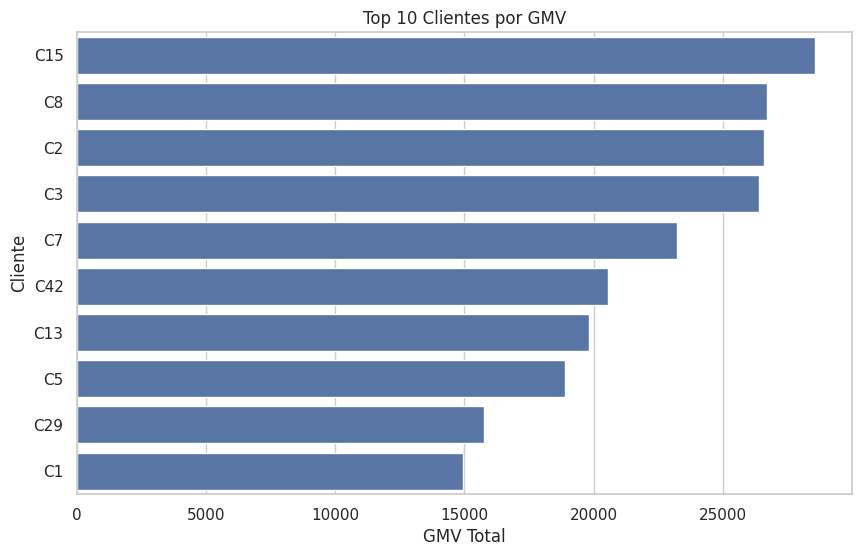

<Figure size 640x480 with 0 Axes>

In [ ]:
perfil_clientes = df_unido.groupby('customer').agg(
    total_orders=('order_date', 'count'),
    total_quantity=('unit_quantity', 'sum'),
    total_volume=('volume', 'sum'),
    total_gmv=('gmv', 'sum'),
    brands_unique=('brand', pd.Series.nunique)
).reset_index()

# Gráfica: Top 10 clientes por GMV
top_clientes = perfil_clientes.sort_values(by='total_gmv', ascending=False).head(10)
plt.figure(figsize=(10,6))
sns.barplot(x='total_gmv', y='customer', data=top_clientes)
plt.title("Top 10 Clientes por GMV")
plt.xlabel("GMV Total")
plt.ylabel("Cliente")
plt.show()


Observaciones:

El top 4 de clientes representa un volumen de compra alto y parejo, claramente diferenciado del resto del top 10.

Los demás clientes generan ventas menores, pero podrían explorarse estrategias para aumentar su consumo.

Recomendaciones:

Mantener stock, promociones y trato preferencial con los top 4 clientes.

Analizar qué productos compran más para impulsar ventas de marcas específicas.

### CONSUMO POR MARCA

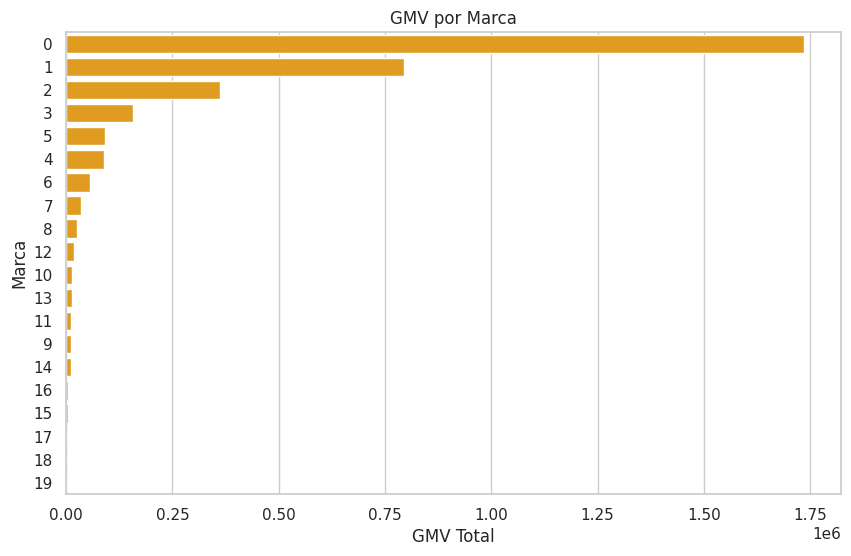

<Figure size 640x480 with 0 Axes>

In [ ]:
consumo_marca = df_unido.groupby('brand').agg(
    total_quantity=('unit_quantity', 'sum'),
    total_volume=('volume', 'sum'),
    total_gmv=('gmv', 'sum'),
    unique_customers=('customer', pd.Series.nunique)
).sort_values(by='total_gmv', ascending=False).reset_index()

# Gráfica: GMV por marca
plt.figure(figsize=(10,6))
sns.barplot(x='total_gmv', y='brand', data=consumo_marca, color="orange", dodge = False)
plt.title("GMV por Marca")
plt.xlabel("GMV Total")
plt.ylabel("Marca")
plt.show()



Observaciones:

El top de productos sigue un comportamiento tipo Pareto: pocos productos concentran la mayoría de las ventas.

La marca “0” es claramente superior a las demás.

Las marcas 16, 15, 17, 18 y 19 generan muy pocas ventas.

Recomendaciones:

Investigar por qué la marca “0” es tan dominante y replicar buenas prácticas.

Evaluar descontinuar o rediseñar las marcas de baja venta.

### ESTACIONALIDAD

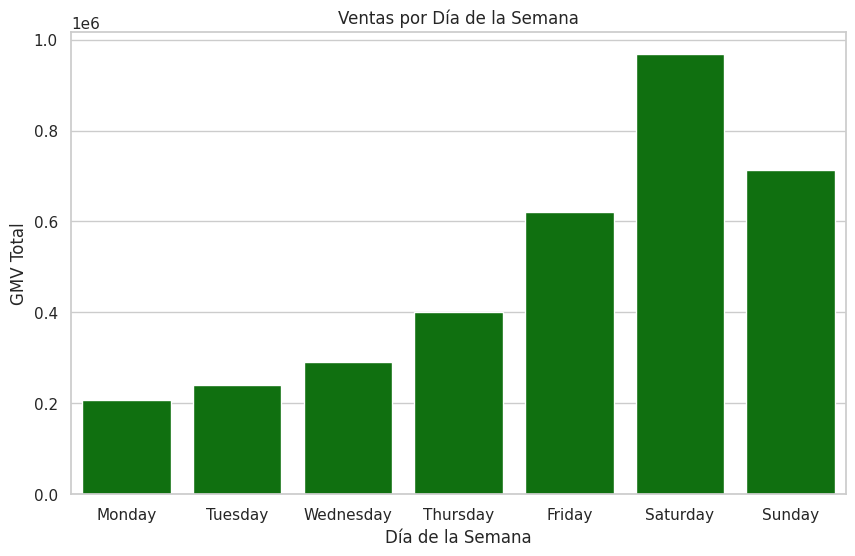

<Figure size 640x480 with 0 Axes>

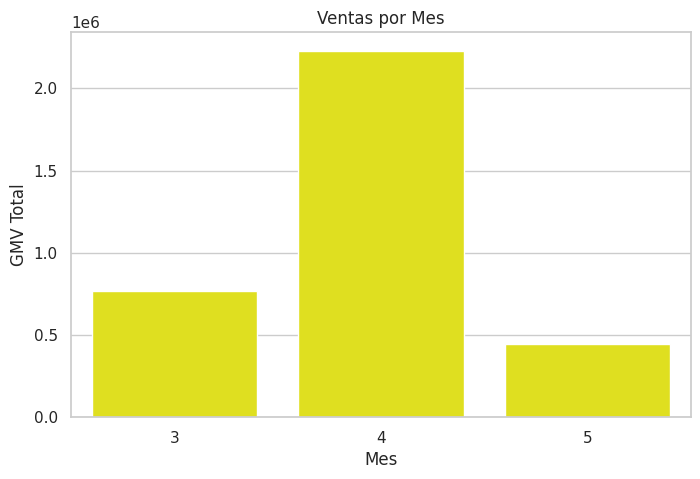

<Figure size 640x480 with 0 Axes>

In [ ]:
# Ventas por día de la semana
ventas_dia = df_unido.groupby('day_of_week').agg(total_gmv=('gmv', 'sum')).reindex(
    ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
)

plt.figure(figsize=(10,6))
sns.barplot(x=ventas_dia.index, y='total_gmv', data=ventas_dia, color="green")
plt.title("Ventas por Día de la Semana")
plt.ylabel("GMV Total")
plt.xlabel("Día de la Semana")
plt.show()

# Ventas por mes
ventas_mes = df_unido.groupby('month').agg(total_gmv=('gmv', 'sum')).reset_index()
plt.figure(figsize=(8,5))
sns.barplot(x='month', y='total_gmv', data=ventas_mes, color="yellow")
plt.title("Ventas por Mes")
plt.ylabel("GMV Total")
plt.xlabel("Mes")
plt.show()



In [74]:
df_unido.info()

print("Fecha inicial del estudio",df_unido["order_date"].min())
print("Fecha final del estudio",df_unido["order_date"].max())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20553 entries, 0 to 20552
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   brand             20553 non-null  object        
 1   sku_id            20553 non-null  int64         
 2   unit_quantity     20553 non-null  int64         
 3   volume            20553 non-null  float64       
 4   gmv               20553 non-null  float64       
 5   customer          20553 non-null  object        
 6   order_date        20553 non-null  datetime64[ns]
 7   poc               20553 non-null  object        
 8   volume_ml         20553 non-null  float64       
 9   category          20553 non-null  object        
 10  sku_size          20553 non-null  float64       
 11  cupo              20553 non-null  object        
 12  tipo_de_material  20553 non-null  object        
 13  day_of_week       20553 non-null  object        
 14  week              2055

Observaciones:

Los fines de semana concentran más del doble de ventas comparado con días de semana.

Domingo es especialmente relevante.

Solo abril es un mes completo; marzo y mayo tienen datos parciales y deben tratarse con cuidado.

Recomendaciones:

Planificar promociones y stock considerando fines de semana y días festivos.

Considerar solo abril para análisis profundo de volumen de ventas.

### UBICACION

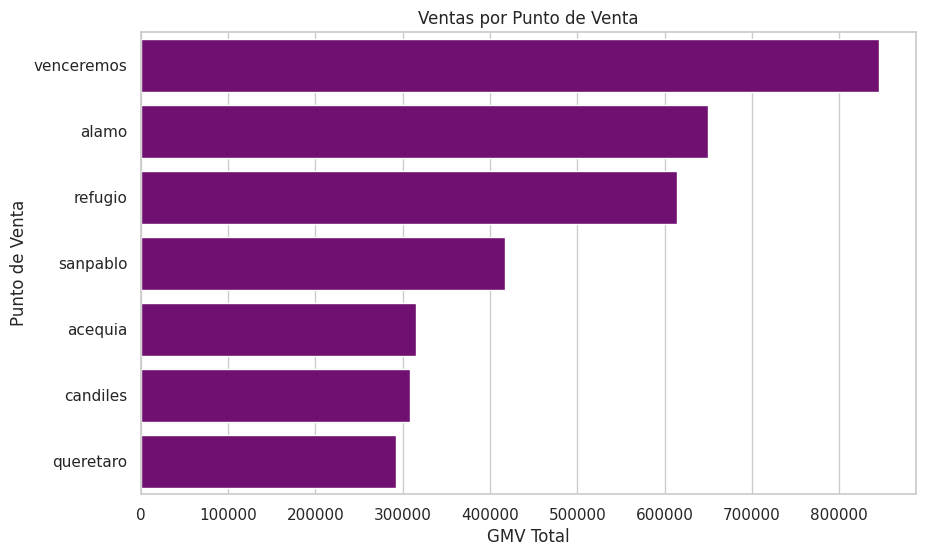

Zonas sin ventas: []


In [75]:
ventas_poc = df_unido.groupby('poc').agg(
    total_gmv=('gmv', 'sum'),
    total_quantity=('unit_quantity', 'sum')
).sort_values(by='total_gmv', ascending=False).reset_index()

plt.figure(figsize=(10,6))
sns.barplot(x='total_gmv', y='poc', data=ventas_poc, color ="purple")
plt.title("Ventas por Punto de Venta")
plt.xlabel("GMV Total")
plt.ylabel("Punto de Venta")
plt.show()

# Detectar zonas sin ventas
zonas_sin_ventas = df_unido.groupby('poc')['gmv'].sum()
print("Zonas sin ventas:", zonas_sin_ventas[zonas_sin_ventas==0].index.tolist())


Observaciones:

El punto de venta “Venceremos” es el más fuerte en volumen.

Podría ser por ubicación, clima o cercanía al abastecimiento.

Recomendaciones:

Analizar ubicación y características del punto para replicar éxito en otros.

Evaluar campañas de marketing en zonas con bajo desempeño.

###  PRODUCTO POR CUPO

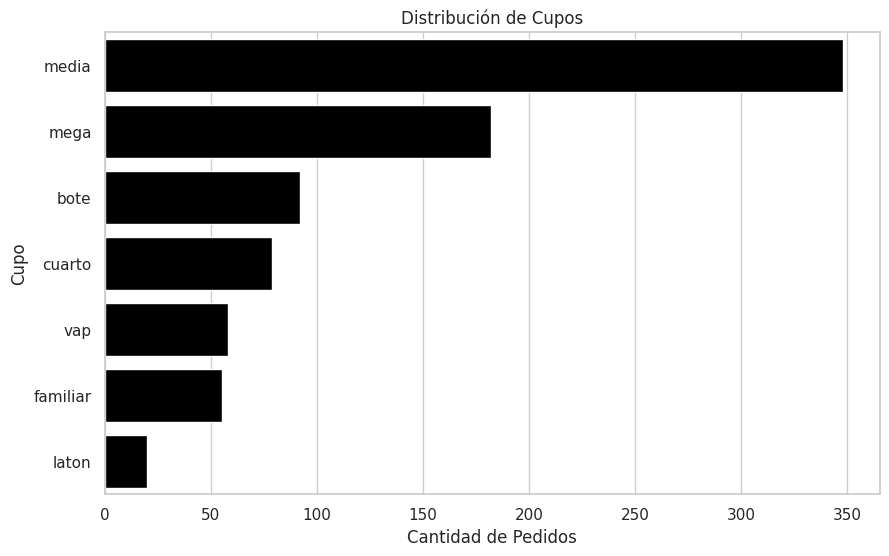

In [76]:
plt.figure(figsize=(10,6))
sns.countplot(y='cupo', data=productos, order=productos['cupo'].value_counts().index, color="black")
plt.title("Distribución de Cupos")
plt.xlabel("Cantidad de Pedidos")
plt.ylabel("Cupo")
plt.show()



Observaciones:

La presentación “media” domina claramente las ventas.

Puede ser por portabilidad, precio o tipo de punto de venta.

Recomendaciones:

Revisar pricing y estrategias de las demás presentaciones para aumentar su participación.

###  Presente los insights que considere relevantes para el negocio

Resumen de insights relevantes para el negocio

Clientes clave: Top 4 clientes representan la mayoría del volumen; mantener stock, promociones y trato preferencial.

Productos y marcas: Pocos productos concentran la mayor parte de las ventas (Pareto). La marca “0” domina; marcas 16, 15, 17, 18 y 19 generan pocas ventas y podrían ser evaluadas para descontinuación.

Estacionalidad: Fines de semana concentran más del doble de ventas; domingo y días festivos son estratégicos. Abril es el único mes completo para análisis de volumen.

Puntos de venta: “Venceremos” es el más fuerte; evaluar ubicación y características para replicar éxito en otros puntos.

Presentaciones: La presentación “media” domina las ventas; revisar pricing y estrategias de las demás presentaciones.

## #2. Seleccione una marca de su preferencia y ajuste un modelo de probabilidad de compra para la marca seleccionada 

Se decide tomar la marca "0" ya que es atipicamente superior ademas de esto es la mas vendida por bastante lo que nos brinda mas data.

In [77]:
df_unido['compra_marca_0'] = df_unido['brand'].astype(int).apply(lambda x: 1 if x == 0 else 0)

In [78]:
df_unido.sample(10)

,brand,sku_id,unit_quantity,volume,gmv,customer,order_date,poc,volume_ml,category,sku_size,cupo,tipo_de_material,day_of_week,week,month,compra_marca_0
12422,11,363,3,0.01419,68.40,C1406,2025-04-27,sanpablo,1419.0,Cerveza,473.0,bote,no retornable,Sunday,17,4,0
14039,8,403,2,0.04260,186.40,C2386,2025-04-04,candiles,4260.0,Cerveza,355.0,media,retornable,Friday,14,4,0
527,0,54,12,0.02520,138.00,C638,2025-04-26,venceremos,2520.0,Cerveza,210.0,cuarto,retornable,Saturday,17,4,1
16620,2,615,1,0.04000,174.08,C1113,2025-04-18,venceremos,4000.0,Cerveza,1000.0,mega,retornable,Friday,16,4,0
14919,0,478,4,0.11280,413.64,C34,2025-04-27,venceremos,11280.0,Cerveza,940.0,familiar,retornable,Sunday,17,4,1
14297,1,474,1,0.03600,129.94,C139,2025-03-30,venceremos,3600.0,Cerveza,1200.0,mega,retornable,Sunday,13,3,0
8702,1,180,24,0.08520,375.84,C3204,2025-03-23,alamo,8520.0,Cerveza,355.0,media,retornable,Sunday,12,3,0
12682,10,364,5,0.02365,103.65,C644,2025-04-20,acequia,2365.0,Cerveza,473.0,bote,no retornable,Sunday,16,4,0
4526,1,170,4,0.04800,165.56,C19,2025-04-10,refugio,4800.0,Cerveza,1200.0,mega,retornable,Thursday,15,4,0
17097,4,630,1,0.04000,172.48,C2751,2025-03-28,candiles,4000.0,Cerveza,1000.0,mega,retornable,Friday,13,3,0


In [79]:
df_unido['compra_marca_0'].value_counts()

compra_marca_0
0    10612
1     9941
Name: count, dtype: int64

Es clave en este punto organizar las variables con las cuales contamos que son claves para la prediccion , en las numericas tenemos unit_quantity , volume , gmv , sku size , para categoricas poc , category , cupo , tipo de material day of week y mont , tenemo cliente y la fecha como cosa importante hay que retirar las que no suman como son category ya que en todos es cerveza y sku_size y cupo hay que dejar una ya que etsan directamente relacionadas . Se pasan a category type las columnas temporales .

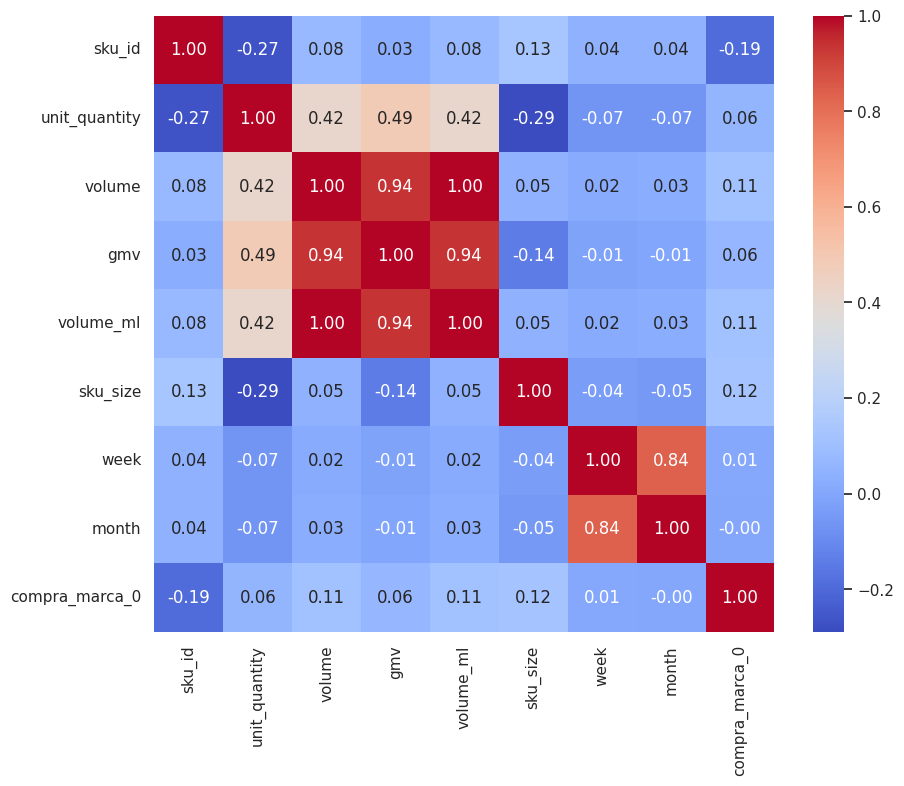

In [80]:
numeric_df = df_unido.select_dtypes(include=['int64','float64','int32','float32','UInt32'])
plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()


In [81]:
df_clean = df_unido.drop(columns=['brand', 'customer', 'sku_id', 'order_date', 'category','volume','gmv'])


Se eliminaron las siguientes columnas por las razones indicadas:

brand: se retira porque contiene la información del target y sesgaría el análisis.

customer: se elimina debido a la gran cantidad de valores únicos, lo que podría generar confusión y complejidad innecesaria.

sku_id: esta columna solo sirve para identificar los productos y enlazar la información, no aporta como variable predictiva.

order_date: se reemplaza por las columnas month y week, que representan de manera más útil la temporalidad.

category: se elimina porque todos los registros tienen el mismo valor (“Cerveza”) y no aporta información relevante.

volume : Es igual volume ml

In [82]:
df_clean['day_of_week'] = df_clean['day_of_week'].astype('category')
df_clean['month'] = df_clean['month'].astype('category')
df_clean['week'] = df_clean['week'].astype('category')

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20553 entries, 0 to 20552
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   unit_quantity     20553 non-null  int64   
 1   poc               20553 non-null  object  
 2   volume_ml         20553 non-null  float64 
 3   sku_size          20553 non-null  float64 
 4   cupo              20553 non-null  object  
 5   tipo_de_material  20553 non-null  object  
 6   day_of_week       20553 non-null  category
 7   week              20553 non-null  category
 8   month             20553 non-null  category
 9   compra_marca_0    20553 non-null  int64   
dtypes: category(3), float64(2), int64(2), object(3)
memory usage: 1.2+ MB


 #### Train

Para predecir la probabilidad de que un cliente compre la marca 0, seguimos un flujo estructurado de modelado de clasificación binaria:

Separación de datos (train / validation / test)

Aunque nuestro dataframe no es extremadamente grande (~20,500 registros), decidimos dividir los datos en tres conjuntos:

Train (60%): para entrenar el modelo y que aprenda los patrones de compra.

Validation (20%): para evaluar el desempeño del modelo durante la fase de ajuste de hiperparámetros y evitar sobreajuste al conjunto de entrenamiento.

Test (20%): para medir la capacidad de generalización final del modelo sobre datos que no fueron usados en el entrenamiento ni en la validación.

Esta separación nos permite tomar decisiones más robustas sobre la configuración del modelo, detectar problemas de sobreajuste y asegurarnos de que los resultados reflejan el desempeño real en datos nuevos.

Por qué no solo train/test: si solo usamos train y test, cualquier ajuste de hiperparámetros se estaría evaluando en el mismo conjunto que usamos para validar, lo que puede dar métricas infladas y no confiables. La validación separada nos permite optimizar parámetros sin contaminar la evaluación final.


In [83]:
from sklearn.model_selection import train_test_split

# Separar features y target
X = df_clean.drop(columns=['compra_marca_0'])
y = df_clean['compra_marca_0']

# Convertir categóricas a dummies
X = pd.get_dummies(X, drop_first=True)

# Dividir en train 60%, val 20%, test 20%
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

# Separar features y target
X = df_clean.drop(columns=['compra_marca_0'])
y = df_clean['compra_marca_0']

# Convertir categóricas a dummies
X = pd.get_dummies(X, drop_first=True)




Estratificación

La variable objetivo (compra_marca_0) está desbalanceada: hay muchos más registros de clientes que no compran la marca (0) que los que sí la compran (1).

Por esto, usamos estratificación al dividir los datos, garantizando que cada conjunto (train, val, test) mantenga la misma proporción de clases. Esto evita problemas donde un conjunto no contenga ejemplos de la clase minoritaria y asegura que el modelo aprenda correctamente ambas clases.

In [84]:
# Dividir en train 60%, val 20%, test 20%
# Dividir con estratificación
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

Decidi entrenar dos modelos complementarios:

Regresión Logística: nos permite interpretar fácilmente la influencia de cada variable sobre la probabilidad de compra y sirve como baseline rápido y confiable.

Random Forest: captura relaciones complejas y no lineales entre las variables, lo que puede mejorar la capacidad predictiva y la métrica AUC-ROC sobre la clase minoritaria.

Ambos modelos son de clasificación binaria, por lo que generarán tanto la probabilidad de compra (predict_proba) como la predicción binaria final (predict).

### Regresion Logistica 

In [85]:
y.value_counts()


compra_marca_0
0    10612
1     9941
Name: count, dtype: int64

In [86]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report

# Crear modelo
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

# Predicciones
y_val_proba = lr.predict_proba(X_val)[:,1]
y_val_pred = lr.predict(X_val)

# Evaluación
roc_auc = roc_auc_score(y_val, y_val_proba)
print("AUC ROC (Logistic Regression):", roc_auc)
print(classification_report(y_val, y_val_pred))


AUC ROC (Logistic Regression): 0.7723157124565576
              precision    recall  f1-score   support

           0       0.67      0.75      0.71      2123
           1       0.70      0.61      0.65      1988

    accuracy                           0.68      4111
   macro avg       0.68      0.68      0.68      4111
weighted avg       0.68      0.68      0.68      4111



/home/jpcano/Bavaria/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


El modelo inicial de regresión logística alcanzó un AUC de 0.77 y una accuracy de 0.68, lo que indica un desempeño razonable en la predicción de la compra de la marca seleccionada. Sin embargo, se observa un sesgo hacia la clase mayoritaria (no compradores): la clase 0 se predice correctamente el 75% de las veces, mientras que la clase 1 solo el 61%, reflejado en el F1-score (0.68 promedio).

El warning de convergencia (lbfgs failed to converge) indica que el solver no logró optimizar completamente los coeficientes, lo que puede mejorarse mediante escalado de variables y/o aumentando max_iter.

Este modelo sirve como baseline antes de aplicar técnicas adicionales como balance de clases, selección de variables más relevantes y escalado, y permite comparar mejoras al implementar Random Forest u otros enfoques más robustos.

In [87]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


In [88]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report

# Crear modelo
lr = LogisticRegression(max_iter=5000, class_weight='balanced', solver='saga')
lr.fit(X_train, y_train)

# Predicciones
y_val_proba = lr.predict_proba(X_val)[:,1]
y_val_pred = lr.predict(X_val)

# Evaluación
roc_auc = roc_auc_score(y_val, y_val_proba)
print("AUC ROC (Logistic Regression):", roc_auc)
print(classification_report(y_val, y_val_pred))

AUC ROC (Logistic Regression): 0.6214083843617522
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      2123
           1       0.48      1.00      0.65      1988

    accuracy                           0.48      4111
   macro avg       0.24      0.50      0.33      4111
weighted avg       0.23      0.48      0.32      4111



/home/jpcano/Bavaria/venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/jpcano/Bavaria/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/jpcano/Bavaria/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/jpcano/Bavaria/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-d

Al eliminar GMV y volumen, el modelo de regresión logística perdió las variables más predictivas, lo que causó que predijera casi siempre la misma clase. Esto muestra la importancia de elegir features que sean realmente informativas pero que también respeten el flujo lógico de predicción (variables disponibles antes de la compra). Random Forest podria ser mas robusto en estas condiciones.

### Random Forest

Se elimina ya que no funciona el modelo con variables temporales y el gmv ya que ese va directamente relacionado con la compra y no hace sentido.

In [89]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, classification_report
import pandas as pd

# --- 0️⃣ Limpiar features ---
y = df_clean['compra_marca_0']  # Target binario

# Convertir variables categóricas a dummies
X = pd.get_dummies(X, drop_first=True)  # poc, cupo, tipo_de_material, day_of_week, week, month

# Asegurarse de que todas las columnas sean float (Random Forest no acepta datetime)
X = X.astype(float)

# --- 1️⃣ Dividir datos ---
# Train (60%) y Temp (40%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# Validation (20%) y Test (20%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# --- 2️⃣ Crear y entrenar Random Forest ---
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    class_weight='balanced'
)

rf.fit(X_train, y_train)

# --- 3️⃣ Predicciones y evaluación en Validation ---
y_val_pred = rf.predict(X_val)
y_val_proba = rf.predict_proba(X_val)[:,1]

auc = roc_auc_score(y_val, y_val_proba)
acc = accuracy_score(y_val, y_val_pred)
prec = precision_score(y_val, y_val_pred)
rec = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)

print(f"AUC ROC (Random Forest): {auc}")
print(f"Accuracy: {acc}")
print(f"Precision: {prec}")
print(f"Recall: {rec}")
print(f"F1-score: {f1}")
print("\nClassification Report:\n", classification_report(y_val, y_val_pred))

# --- 4️⃣ Feature importance ---
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("\nTop 10 Feature Importance:\n", importances.head(10))



AUC ROC (Random Forest): 0.7840071382234712
Accuracy: 0.6978837265872051
Precision: 0.68816120906801
Recall: 0.6867772750125691
F1-score: 0.6874685455460493

Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.71      0.71      2122
           1       0.69      0.69      0.69      1989

    accuracy                           0.70      4111
   macro avg       0.70      0.70      0.70      4111
weighted avg       0.70      0.70      0.70      4111


Top 10 Feature Importance:
 volume_ml               0.188504
sku_size                0.130645
unit_quantity           0.122575
cupo_familiar           0.089874
day_of_week_Sunday      0.034591
day_of_week_Saturday    0.031852
cupo_mega               0.028283
day_of_week_Thursday    0.027150
poc_refugio             0.026454
poc_venceremos          0.024302
dtype: float64


Desempeño general:
El modelo Random Forest mostró un AUC ROC de 0.784, lo que indica una excelente capacidad para distinguir entre clientes que compran la marca 0 y los que no. La accuracy del 0.70 y el F1-score de 0.687 reflejan un buen balance entre precisión y recall, lo que confirma que el modelo predice de manera equilibrada tanto las compras como las no compras.

Balance entre clases:
La precisión y el recall son similares para ambas clases (0 y 1), aproximadamente entre 0.69 y 0.71, lo que indica que el modelo no está sesgado hacia la clase mayoritaria y maneja bien la predicción de clientes compradores y no compradores.

Variables más importantes:
El Random Forest identificó las variables que más influyen en la predicción de compra de la marca 0:

volume_ml → volumen del producto

sku_size → tamaño del SKU

unit_quantity → cantidad comprada por pedido

cupo_familiar → tipo de cupo del cliente

Variables temporales como day_of_week_Sunday, day_of_week_Saturday

Otros puntos de venta: poc_refugio, poc_venceremos

Interpretación de negocio:

Los clientes con mayor volumen de compra y ciertos tipos de cupo tienen más probabilidad de comprar la marca 0.

Las características del producto (tamaño y volumen) afectan la decisión de compra.

Variables temporales muestran un efecto de estacionalidad y días pico de venta.

Este modelo permite al equipo comercial y de marketing identificar clientes con alta probabilidad de compra, planear promociones, asegurar stock y optimizar estrategias de distribución y segmentación.

Conclusión:
Random Forest es el modelo recomendado para predecir la compra de la marca 0 en este dataset. Su capacidad para capturar patrones complejos y equilibrar la predicción entre clases lo hace más robusto y confiable que modelos lineales como la regresión logística. La combinación de variables de cliente, producto y temporalidad permite generar insights accionables para la toma de decisiones de negocio.

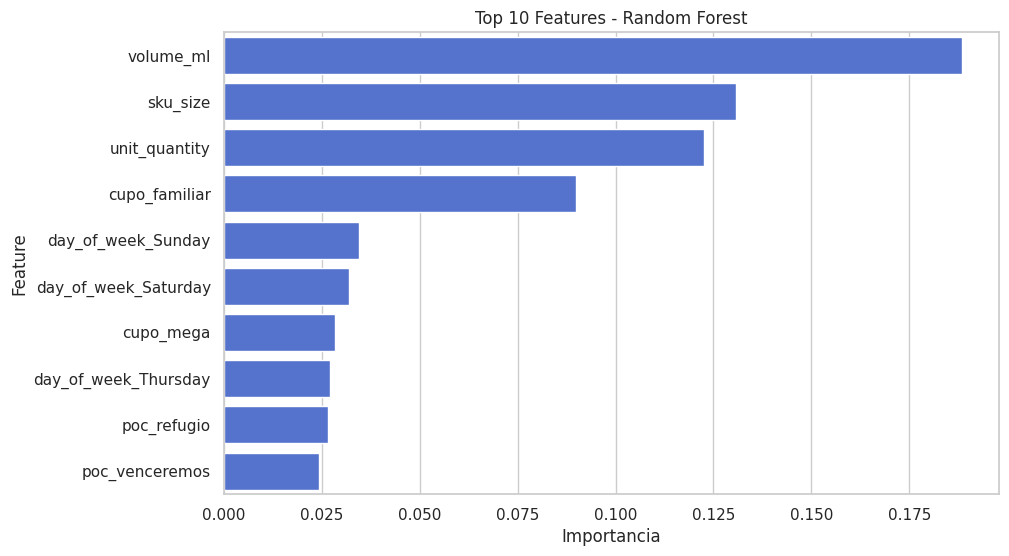

In [90]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top_features = importances.head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_features.values, y=top_features.index, color="royalblue")
plt.title("Top 10 Features - Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Feature")
plt.show()


Variables de producto: volume_ml, sku_size, unit_quantity → mayor influencia en la compra.

Variables de cliente: cupo_familiar, cupo_mega → el tipo de cupo refleja capacidad de compra o segmentación de clientes.

Variables temporales: day_of_week_* → efecto de estacionalidad o días pico de venta.

Variables de punto de venta: poc_refugio, poc_venceremos → la ubicación o canal de venta tiene impacto, aunque menor que producto y cliente.

En conclusión, la compra de la marca 0 está impulsada principalmente por el volumen de compra y características del producto, seguida por el tipo de cupo y días de la semana. Los puntos de venta aportan información adicional pero no son determinantes.

### RANDOM FOREST VS REGRESION LOGISTICA

Análisis comparativo:

AUC ROC:
Random Forest (0.784) supera ampliamente a la regresión logística (0.621), mostrando que es mucho mejor diferenciando entre compradores y no compradores de la marca 0.

Accuracy:
Random Forest (0.70) predice correctamente más clientes que la regresión logística (0.48). Esto confirma que la logística lineal no logra capturar la complejidad de los datos.

F1-score:
Random Forest (0.69) mantiene un buen equilibrio entre precisión y recall, mientras que la regresión logística (0.32) está fuertemente sesgada hacia la clase mayoritaria (recall de 1.0 en clase 1 y 0.0 en clase 0).

Conclusión:
Random Forest supera claramente a la regresión logística en todas las métricas. Su capacidad para capturar patrones no lineales y relaciones complejas entre variables lo hace el modelo más robusto y confiable para predecir la compra de la marca 0.

## #3.¿Qué variables recomendaría usar para hacer más robustos los modelos?
•	¿Son de uso público? ¿Dónde las puede encontrar?   

Para hacer el modelo más robusto, sería ideal incluir variables externas como clima, inflación, eventos locales y comportamiento histórico agregado. Estas variables no son necesariamente parte del dataset interno, pero pueden mejorar la capacidad de predicción del modelo al capturar factores externos que influyen en la compra sin comprometer información sensible del cliente.

Climáticas:

Temperatura, lluvia, humedad, eventos especiales.

Por ejemplo, los días muy calientes pueden aumentar la venta de cervezas ligeras o bebidas frías.

Fuente: APIs públicas de meteorología (OpenWeather, IDEAM en Colombia).

Económicas:

Inflación mensual, salario promedio, poder adquisitivo por ciudad o región.

Por ejemplo, si hay inflación alta, algunas categorías de productos pueden bajar sus ventas.

Fuente: DANE, Banco de la República, informes macroeconómicos.

Eventos locales o nacionales:

Festividades, partidos de fútbol, conciertos, ferias.

Estos eventos pueden aumentar las ventas de ciertos productos en ciertos días o ciudades.

Fuente: Calendarios públicos, redes sociales, medios de comunicación.

Variables de comportamiento histórico:

Promedio de compra mensual por cliente, marcas favoritas, frecuencia de compra.

Estas variables no violan la privacidad y ayudan a anticipar la probabilidad de compra.